# Failure of linear models

Heading is plotted against the direction of groundspeed, airspeed and thrust for the heading-corrected data (`pipelinedata/05_final/`). A free-slope circular (Möbius) regression is overlaid on each panel with its circular R². Heading and all three predictors are angles, so a linear fit on the raw values would be unfair.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.colors as mcolors
sys.path.insert(0, os.path.abspath('../utils'))
from utils import make_color_map

df = pd.read_csv('../pipelinedata/05_final/all_wind_heading_and_trajectories_augmented_corrected_filtered_headx_heady.csv')
cols = ['heading_angle', 'groundspeed_angle', 'airspeed_angle', 'thrust_angle']
df = df[cols].dropna()
TWO_PI = 2 * np.pi
heading = df['heading_angle'].values % TWO_PI
predictors = [
    ('Groundspeed direction (rad)', df['groundspeed_angle'].values % TWO_PI),
    ('Airspeed direction (rad)',    df['airspeed_angle'].values % TWO_PI),
    ('Thrust direction (rad)',      df['thrust_angle'].values % TWO_PI),
]
len(df)

113738

## Circular regression (free slope)

Möbius (Downs–Mardia) circular-circular regression: $\hat\theta_h = \mu + 2\arctan\!\left(\beta \tan\frac{\theta_x - \nu}{2}\right)$, with free rotation $\mu$, free input origin $\nu$ and free slope $\beta > 0$ (β = 1 is a pure rotation; β > 1 steepens the map around ν). Parameters minimise $\sum(1-\cos e_i)$, the circular residual, from several starting points. Circular $R^2 = 1 - \sum(1-\cos e_i) / \sum(1-\cos(\theta_{h,i}-\bar\theta_h))$: 1 for a perfect fit, 0 for no better than the circular mean.

In [2]:
from scipy.optimize import minimize

def circular_mean(a):
    return np.arctan2(np.sin(a).mean(), np.cos(a).mean())

def mobius(x, mu, nu, log_beta):
    return mu + 2 * np.arctan(np.exp(log_beta) * np.tan((x - nu) / 2))

def circular_regression(x, y):
    loss = lambda p: np.mean(1 - np.cos(y - mobius(x, *p)))
    best = None
    for nu0 in np.linspace(0, TWO_PI, 8, endpoint=False):
        for lb0 in (-1.0, 0.0, 1.0, 2.0):
            res = minimize(loss, [circular_mean(y - x), nu0, lb0], method='Nelder-Mead',
                           options=dict(xatol=1e-6, fatol=1e-10, maxiter=4000))
            if best is None or res.fun < best.fun:
                best = res
    params = best.x
    resid = y - mobius(x, *params)
    ss_res = np.sum(1 - np.cos(resid))
    ss_tot = np.sum(1 - np.cos(y - circular_mean(y)))
    return params, 1 - ss_res / ss_tot

fits = [circular_regression(x, heading) for _, x in predictors]
for (name, _), (p, r2) in zip(predictors, fits):
    print(f'{name}: mu = {p[0] % TWO_PI:.3f}, nu = {p[1] % TWO_PI:.3f}, beta = {np.exp(p[2]):.2f}, circular R^2 = {r2:.3f}')

Groundspeed direction (rad): mu = 6.273, nu = 0.013, beta = 3.59, circular R^2 = 0.152
Airspeed direction (rad): mu = 0.096, nu = 0.074, beta = 0.62, circular R^2 = 0.459
Thrust direction (rad): mu = 5.482, nu = 5.425, beta = 1.17, circular R^2 = 0.290


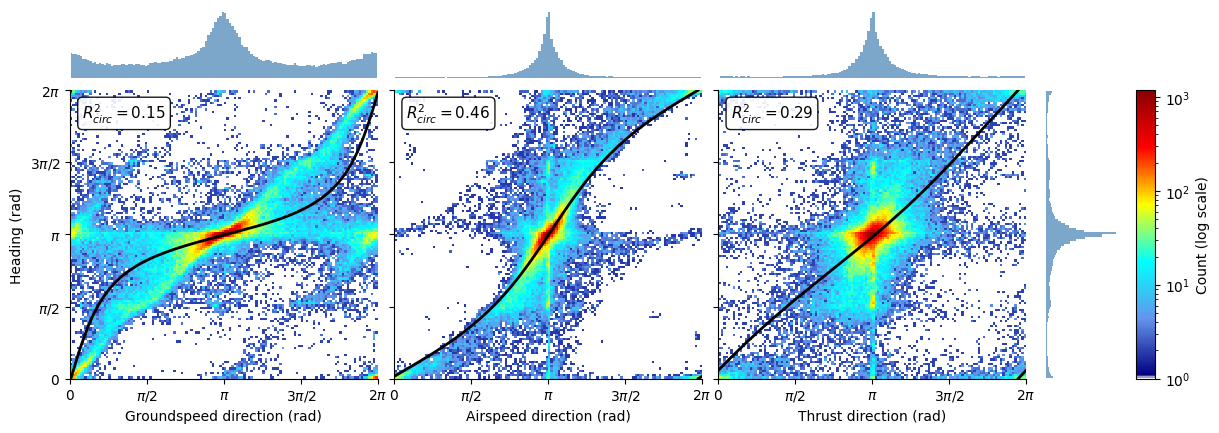

In [3]:
cmap = make_color_map(color_list=['white', 'navy', 'cornflowerblue', 'aqua', 'yellow', 'red', 'darkred'], N=256)
PI_TICKS  = [0, np.pi/2, np.pi, 3*np.pi/2, TWO_PI]
PI_LABELS = [r'$0$', r'$\pi/2$', r'$\pi$', r'$3\pi/2$', r'$2\pi$']
N_BINS = 128

def heatmap(ax, x, y, show_ylabel):
    h, xe, ye = np.histogram2d(x, y, bins=N_BINS, range=[[0, TWO_PI]] * 2)
    im = ax.pcolormesh(xe, ye, np.ma.masked_where(h.T == 0, h.T),
                       norm=mcolors.LogNorm(vmin=1, vmax=h.max()), cmap=cmap, rasterized=True)
    ax.set_xlim(0, TWO_PI); ax.set_ylim(0, TWO_PI)
    ax.set_xticks(PI_TICKS); ax.set_xticklabels(PI_LABELS)
    ax.set_yticks(PI_TICKS); ax.set_yticklabels(PI_LABELS if show_ylabel else [''] * 5)
    if show_ylabel:
        ax.set_ylabel('Heading (rad)', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
    return im

def regression_line(ax, params, r2):
    xs = np.linspace(0, TWO_PI, 2000)
    ys = mobius(xs, *params) % TWO_PI
    ys[np.r_[False, np.abs(np.diff(ys)) > np.pi]] = np.nan  # break the line at the 2pi seam
    ax.plot(xs, ys, color='black', lw=2, label='circular regression')
    ax.text(0.04, 0.96, rf'$R^2_{{circ}} = {r2:.2f}$', transform=ax.transAxes, va='top', ha='left',
            fontsize=11, bbox=dict(boxstyle='round', fc='white', ec='black', alpha=0.9))

fig = plt.figure(figsize=(14, 4.8))
gs = gridspec.GridSpec(2, 5, figure=fig, width_ratios=[4, 4, 4, 1, 0.25],
                       height_ratios=[1, 4], hspace=0.05, wspace=0.08)
for i, ((name, x), (params, r2)) in enumerate(zip(predictors, fits)):
    ax_top  = fig.add_subplot(gs[0, i])
    ax_main = fig.add_subplot(gs[1, i])
    im = heatmap(ax_main, x, heading, show_ylabel=(i == 0))
    regression_line(ax_main, params, r2)
    ax_main.set_xlabel(name, fontsize=10)
    counts, edges = np.histogram(x, bins=N_BINS, range=(0, TWO_PI))
    ax_top.fill_between(0.5 * (edges[:-1] + edges[1:]), counts, step='mid', color='steelblue', alpha=0.7, lw=0)
    ax_top.set_xlim(0, TWO_PI); ax_top.set_xticks([]); ax_top.set_yticks([])
    for s in ax_top.spines.values(): s.set_visible(False)

# one shared heading marginal on the right (heading is the y-axis in every panel)
ax_right = fig.add_subplot(gs[1, 3])
counts, edges = np.histogram(heading, bins=N_BINS, range=(0, TWO_PI))
ax_right.fill_betweenx(0.5 * (edges[:-1] + edges[1:]), counts, step='mid', color='steelblue', alpha=0.7, lw=0)
ax_right.set_ylim(0, TWO_PI); ax_right.set_xticks([]); ax_right.set_yticks([])
for s in ax_right.spines.values(): s.set_visible(False)

cbar = fig.colorbar(im, cax=fig.add_subplot(gs[1, 4]), label='Count (log scale)')
cbar.ax.yaxis.label.set_size(10)

os.makedirs('../figures', exist_ok=True)
fig.savefig('../figures/failure_of_linear_models.pdf', bbox_inches='tight')
fig.savefig('../figures/failure_of_linear_models.png', dpi=300, bbox_inches='tight')
plt.show()